Portfolio Value at Risk (VaR) Estimation: GARCH-Monte Carlo Simulation for EUR/USD
**Author:** Nikhil Srivastava
**Group / Organization:** 2 Lines of Defense
**Date:** September 23, 2026  

---

## i. Brief Background / Introduction

Value at Risk (VaR) is a standard risk-management metric used across modern banking institutions to quantify the potential financial loss of an asset or portfolio over a specified time horizon for a given confidence level. Foreign exchange (FX) markets are characterized by time-varying volatility, dynamic variance clustering, and heavy-tailed yield distributions, making traditional static variance assumptions (such as standard normal distribution models) inadequate.

This project develops an advanced market risk measurement framework for a **EUR/USD foreign exchange portfolio**. The framework combines a **Generalized Autoregressive Conditional Heteroskedasticity (GARCH(1,1))** model to capture time-varying volatility dynamics with a **Monte Carlo Simulation** methodology to project potential portfolio loss distributions over a specified horizon. Using historical EUR/USD daily closing price data from **2021 through 2026**, this project evaluates market exposure to support daily risk management and capital reserve requirements.

---

## ii. Problem Statement and Business Context

### Problem Statement
Standard regulatory capital frameworks (e.g., Basel III/IV) require financial institutions to hold sufficient capital reserves against potential market losses. Traditional linear VaR models (e.g., Variance-Covariance) fail during market stress because they assume constant volatility and normally distributed returns. This leads to:
1. **Underestimation of Tail Risk:** Failure to account for extreme market drawdowns ("fat tails").
2. **Inaccurate Capital Reserves:** Misestimating risk exposures, leading to inefficient capital allocation or regulatory penalties.

### Business Context
For a bank trading desk holding currency positions in EUR/USD, sharp movements driven by macroeconomic developments (e.g., ECB/Federal Reserve rate policy shifts, geopolitical shocks) create significant market risk. Implementing a hybrid dynamic VaR framework using **GARCH + Monte Carlo** solves this by:
* Dynamically updating risk estimates based on current market volatility regimes.
* Simulating thousands of forward return paths to capture complex tail outcomes accurately.
* Supporting compliance with Basel Committee market risk standards (e.g., Fundamental Review of the Trading Book - FRTB).

---

## iii. Scope of Model

* **Underlying Asset Class:** Foreign Exchange (FX).
* **Target Currency Pair:** EUR/USD (spot rates).
* **Data Horizon:** Daily closing prices from **January 2021 to September 2026**.
* **Risk Metric:** Value at Risk (VaR) at **95%** and **99%** confidence levels.
* **Holding Horizon:** 1-day forward (scalable to 10-day using standard square-root time rules or multi-step simulation).
* **Out of Scope:** Multi-asset cross-currency portfolios, interest rate differentials (carry trade risk), options/derivatives pricing models, and intra-day high-frequency trading dynamics.

---

## iv. Model Outline and Assumptions

### 1. Data Transformation (Log Returns)
Given daily spot price sequence $P_t$, simple returns are transformed into logarithmic returns $r_t$ to enforce time-additivity:

$$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$$

### 2. GARCH(1,1) Volatility Model
To capture volatility clustering, the dynamic conditional variance $\sigma_t^2$ is modeled as:

$$r_t = \mu + \epsilon_t, \quad \text{where } \epsilon_t = \sigma_t z_t \quad \text{and } z_t \sim \text{i.i.d. } \mathcal{N}(0, 1) \text{ or } t(\nu)$$

$$\sigma_t^2 = \omega + \alpha \epsilon_{t-1}^2 + \beta \sigma_{t-1}^2$$

Where:
* $\omega > 0$: Baseline constant variance.
* $\alpha \ge 0$: Reaction to recent market shocks (ARCH term).
* $\beta \ge 0$: Persistence of past volatility (GARCH term).
* Stationarity constraint: $\alpha + \beta < 1$.

### 3. Monte Carlo Simulation Engine
1. Estimate $\hat{\mu}, \hat{\omega}, \hat{\alpha}, \hat{\beta}$ from historical EUR/USD returns (2021–2026).
2. Extract the current spot price $P_T$ and the predicted baseline conditional volatility $\sigma_{T+1}$.
3. Draw $N$ standard random shocks $z_i \sim \mathcal{D}(0,1)$ (e.g., $N = 100,000$ iterations).
4. Simulate forward 1-day returns:

$$r_{T+1, i} = \hat{\mu} + \sigma_{T+1} z_i$$

5. Compute simulated portfolio value outcomes $V_{T+1, i} = V_T \cdot \exp(r_{T+1, i})$.
6. Value at Risk (VaR) at confidence level $1 - \alpha$ is the $\alpha$-quantile of simulated losses:

$$\text{VaR}_{\alpha} = V_T - \text{Percentile}\left(\{V_{T+1, i}\}_{i=1}^N, \alpha \times 100\right)$$

### Model Assumptions
1. **Stationarity:** The underlying process driving conditional parameters remains stationary over the calibration window.
2. **Distributional Structure:** Innovations $z_t$ are assume to follow a specified distribution (Standard Normal or Student’s $t$-distribution for heavy tails).
3. **No Liquidity Constraints:** Positions can be liquidated instantly at the prevailing market closing price without market impact.

---

## v. Model Implementation

To deploy this model within an institutional workflow or automated notebook script, follow these steps:

1. **Data Ingestion & Cleaning:**
   * Fetch daily EUR/USD closing prices $P_t$ spanning 2021–2026 from verified market feeds (e.g., Bloomberg, Refinitiv, Yahoo Finance API).
   * Check for missing dates, market holidays, and zero-volume days; backfill or filter appropriately.

2. **Model Parameter Estimation:**
   * Fit the GARCH(1,1) model on $r_t$ using Maximum Likelihood Estimation (MLE) (e.g., Python `arch` package).
   * Save calibrated parameters $(\hat{\mu}, \hat{\omega}, \hat{\alpha}, \hat{\beta})$.

3. **Simulation Execution:**
   * Generate $N = 100,000$ standardized random draws ($z$).
   * Calculate $\sigma_{T+1}$ using the fitted GARCH state equation.
   * Project simulated end-of-day portfolio values.

4. **Risk Calculation & Reporting:**
   * Extract $95\%$ and $99\%$ VaR quantile losses.
   * Output visual dashboards: historical yield plots, GARCH conditional volatility series, and simulated return loss distribution curves.

---

## vi. Limitations of Model and Ongoing Monitoring

### Model Limitations
1. **Model Parameter Sensitivity:** GARCH parameters are highly sensitive to extreme regime shifts (e.g., sudden financial crises or unexpected central bank rate decisions).
2. **Distributional Misspecification:** If standard normal distributions are assumed for innovations $z_t$, extreme tail events may still be underestimated compared to Student's $t$ or skewed distributions.
3. **Single Asset Focus:** Does not account for dynamic correlations with other currency pairs or cross-asset feedback loops.

### Ongoing Monitoring & Governance
* **Daily Backtesting (Kupiec POF Test):** Compare actual EOD daily portfolio returns against predicted VaR levels. If the number of exceptions exceeds regulatory limits (e.g., >2.5% for 97.5% VaR), trigger model re-calibration.
* **Stress Testing & Scenario Analysis:** Supplement VaR metrics with historical stress tests (e.g., 2008 global financial crisis shock, post-pandemic inflation spikes) to account for tail-risk breaks.
* **Periodic Parameter Re-estimation:** Re-fit GARCH parameters monthly or quarterly to ensure parameters adapt to changing volatility regimes.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
import yfinance as yf

In [4]:
data = yf.download(
    "EURUSD=X",
    start="2021-09-21",
    end="2026-09-21",
    interval="1d",
    auto_adjust=False
)
master = data.copy()

[*********************100%***********************]  1 of 1 completed


In [5]:
data.head()

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,EURUSD=X,EURUSD=X,EURUSD=X,EURUSD=X,EURUSD=X,EURUSD=X
Date,,,,,,
2021-09-21,1.173020,1.173020,1.174895,1.171591,1.172567,0
2021-09-22,1.172292,1.172292,1.174453,1.171715,1.172608,0
2021-09-23,1.168770,1.168770,1.175101,1.168419,1.168893,0
2021-09-24,1.174026,1.174026,1.174812,1.170166,1.174178,0
2021-09-27,1.172305,1.172305,1.172800,1.168661,1.172209,0


In [6]:
data.columns

MultiIndex([('Adj Close', 'EURUSD=X'),
            (    'Close', 'EURUSD=X'),
            (     'High', 'EURUSD=X'),
            (      'Low', 'EURUSD=X'),
            (     'Open', 'EURUSD=X'),
            (   'Volume', 'EURUSD=X')],
           names=['Price', 'Ticker'])

In [7]:
master.columns = data.columns.droplevel('Ticker')
master = master.reset_index()
master.tail()
master.to_csv('Euro_USD_Forex_2021_2026')

/var/folders/hw/zd2rr21d5s379c_0r4sb63dr0000gn/T/ipykernel_37728/2692755401.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


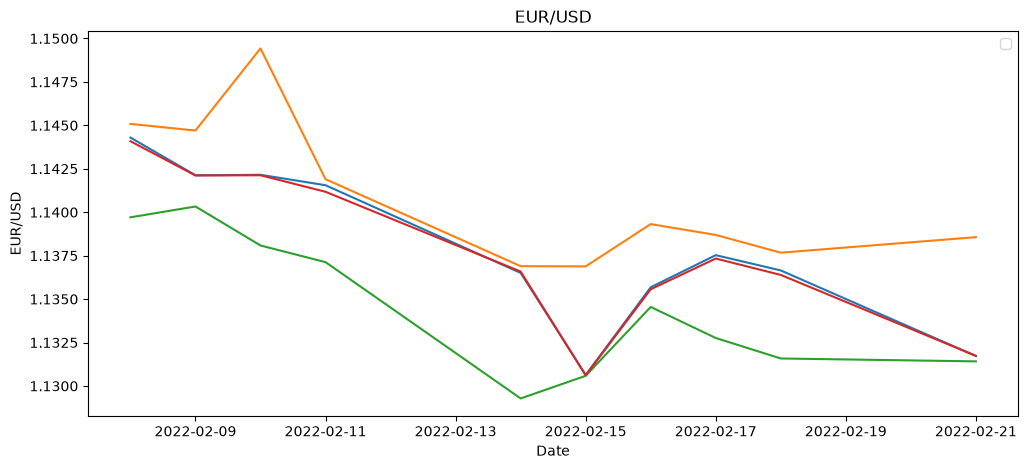

In [8]:
plt.figure(figsize=(12,5))
plt.plot(master['Date'][100:110], master[['Close','High','Low','Open']][100:110])
plt.xlabel('Date')
plt.ylabel('EUR/USD')
plt.legend()
plt.title('EUR/USD')
plt.show()

In [9]:
df = data[['Close']].reset_index()
df.columns = ['Date','Close']

In [10]:
df.head(10)

,Date,Close
0,2021-09-21,1.173020
1,2021-09-22,1.172292
2,2021-09-23,1.168770
3,2021-09-24,1.174026
4,2021-09-27,1.172305
5,2021-09-28,1.169680
6,2021-09-29,1.168634
7,2021-09-30,1.160160
8,2021-10-01,1.157448
9,2021-10-04,1.160726


In [11]:
df['log_return'] = np.log(df['Close']/df['Close'].shift(1))

In [12]:
df.head(10)

,Date,Close,log_return
0,2021-09-21,1.173020,NaN
1,2021-09-22,1.172292,-0.000622
2,2021-09-23,1.168770,-0.003008
3,2021-09-24,1.174026,0.004486
4,2021-09-27,1.172305,-0.001466
5,2021-09-28,1.169680,-0.002242
6,2021-09-29,1.168634,-0.000894
7,2021-09-30,1.160160,-0.007277
8,2021-10-01,1.157448,-0.002341
9,2021-10-04,1.160726,0.002828


In [13]:
df.dtypes

Date          datetime64[s]
Close               float64
log_return          float64
dtype: object

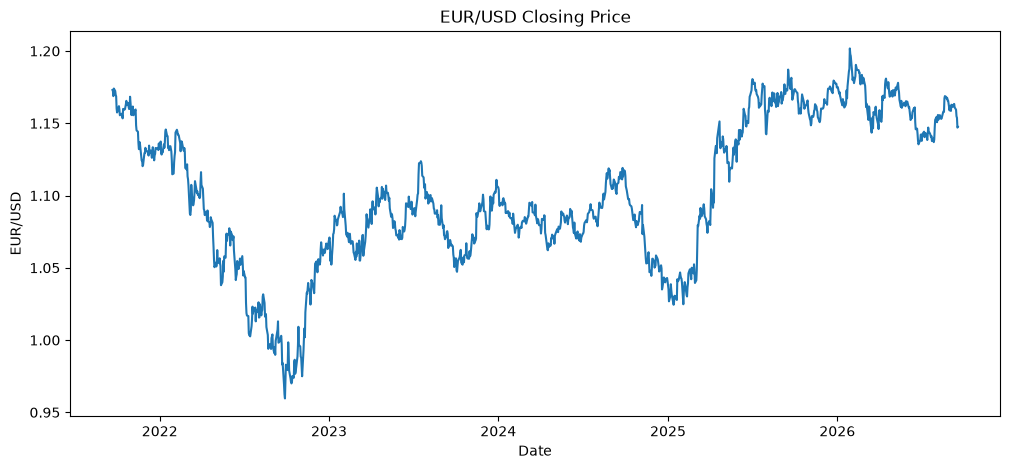

In [14]:
plt.figure(figsize=(12,5))
plt.plot(df['Date'], df['Close'])
plt.xlabel('Date')
plt.ylabel('EUR/USD')
plt.title('EUR/USD Closing Price')
plt.show()

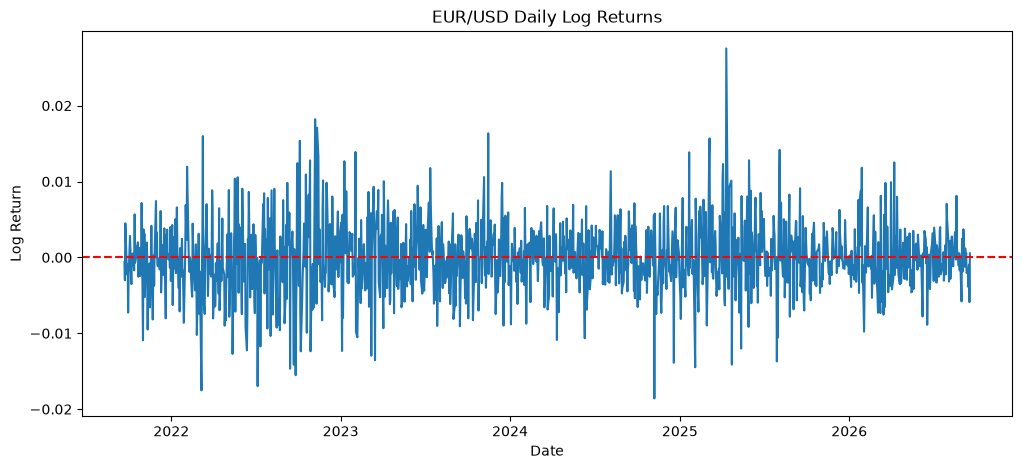

In [15]:
plt.figure(figsize=(12,5))
plt.plot(df['Date'], df['log_return'])
plt.axhline(0, linestyle='--', color = 'r')
plt.xlabel('Date')
plt.ylabel('Log Return')
plt.title('EUR/USD Daily Log Returns')
plt.show()

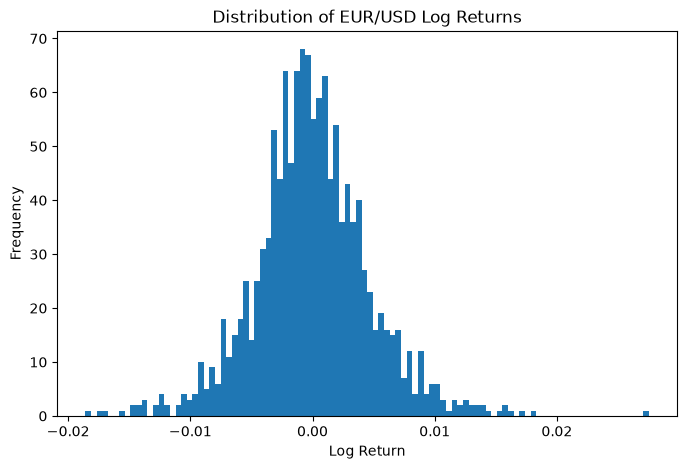

In [16]:
plt.figure(figsize=(8,5))
plt.hist(df['log_return'].dropna(), bins=100)
plt.xlabel('Log Return')
plt.ylabel('Frequency')
plt.title('Distribution of EUR/USD Log Returns')
plt.show()

In [17]:
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_arch
from statsmodels.stats.diagnostic import acorr_ljungbox

In [18]:
import warnings
from scipy import stats
from scipy.special import xlogy
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# !pip install arch        # <- uncomment if the `arch` package is not installed
from arch import arch_model
from arch.utility.exceptions import DataScaleWarning

# rescale=False is used everywhere below so all parameters stay in (percent) units
warnings.filterwarnings("ignore", category=DataScaleWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": True, "grid.alpha": 0.3})

# Part 1: Stationarity and GARCH-eligibility tests

GARCH models the **variance** of a series that is itself (weakly) stationary with an (approximately) constant mean, so the checks are:

1. **Stationarity (ADF + KPSS).** ADF null = unit root; KPSS null = stationary. We want *ADF rejects* and *KPSS fails to reject*. Prices are expected to fail, log-returns to pass.
2. **Mean dynamics (Ljung-Box on returns).** No serial correlation means a constant mean equation is enough.
3. **ARCH effects (Ljung-Box on squared returns, ARCH-LM).** The real prerequisite: variance must be time-varying and autocorrelated, otherwise GARCH adds nothing.
4. **Normality (Jarque-Bera, kurtosis).** Decides whether to use Normal or Student-t innovations.

In [19]:
def stationarity_report(series, name):
    s = series.dropna()
    adf_stat, adf_p, *_ = adfuller(s, autolag="AIC")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")              # KPSS p-values are clipped to [0.01, 0.10]
        kpss_stat, kpss_p, *_ = kpss(s, regression="c", nlags="auto")
    if adf_p < 0.05 and kpss_p > 0.05:
        verdict = "Stationary"
    elif adf_p >= 0.05 and kpss_p <= 0.05:
        verdict = "Non-stationary"
    else:
        verdict = "Inconclusive (tests disagree)"
    return {"Series": name, "ADF stat": adf_stat, "ADF p": adf_p,
            "KPSS stat": kpss_stat, "KPSS p": kpss_p, "Verdict": verdict}

stat_table = pd.DataFrame([
    stationarity_report(df["Close"], "EUR/USD price (level)"),
    stationarity_report(np.log(df["Close"]), "log price"),
    stationarity_report(df["log_return"], "log return (1st difference of log price)"),
]).set_index("Series")
stat_table.round(4)

,ADF stat,ADF p,KPSS stat,KPSS p,Verdict
Series,,,,,
EUR/USD price (level),-1.7755,0.3927,2.2511,0.01,Non-stationary
log price,-1.7845,0.3882,2.2090,0.01,Non-stationary
log return (1st difference of log price),-12.9362,0.0000,0.1930,0.10,Stationary


### 1b. Mean reversion and ARCH effects (your function, index-alignment bug fixed)
`analyze_returns` crashed with *"indices for endog and exog are not aligned"* because of an extra `.iloc[1:]` on the lagged series; that line is removed. Note that for **returns** the OU regression slope is ~ -1 by construction (half-life < 1 day), i.e. returns have no slow mean reversion and are close to white noise in the mean. The ARCH-LM and Ljung-Box (squared returns) tests are the ones that matter for GARCH.

In [20]:
def analyze_returns(series):
    s = series.dropna()

    # --- MEAN REVERSION TESTS ---
    # 1. Half-Life Calculation via Ornstein-Uhlenbeck
    lagged = s.shift(1).dropna()
    delta = (s - lagged).dropna()

    X = sm.add_constant(lagged)
    model = sm.OLS(delta, X).fit()
    lambda_param = model.params.iloc[1]

    if lambda_param < 0:
        half_life = -np.log(2) / lambda_param
        print(f"Mean Reversion Speed (lambda): {lambda_param:.4f}")
        print(f"Half-Life of Mean Reversion: {half_life:.2f} periods")
    else:
        print("Series is NOT mean-reverting (lambda >= 0).")

    print("\n" + "=" * 45 + "\n")

    # --- CONSTANT VOLATILITY TESTS ---
    # 2. ARCH-LM Test
    arch_test = het_arch(s)
    print("--- ARCH-LM Test for Volatility Clustering ---")
    print(f"LM Statistic: {arch_test[0]:.4f}")
    print(f"p-value: {arch_test[1]:.4f}")
    if arch_test[1] < 0.05:
        print("=> Reject Null: Volatility is NOT constant (ARCH effects present).")
    else:
        print("=> Fail to Reject: Volatility is constant.")

    print("\n" + "=" * 45 + "\n")

    # 3. Ljung-Box Test on Squared Returns
    lb_test = acorr_ljungbox(s**2, lags=[10], return_df=True)
    p_val = lb_test["lb_pvalue"].values[0]
    print("--- Ljung-Box Test on Squared Returns (Lag 10) ---")
    print(f"p-value: {p_val:.4f}")
    if p_val < 0.05:
        print("=> Reject Null: Autocorrelation in volatility detected.")
    else:
        print("=> Fail to Reject: No volatility autocorrelation.")


# Execute on your series
analyze_returns(df['log_return'])

Mean Reversion Speed (lambda): -0.9946
Half-Life of Mean Reversion: 0.70 periods


--- ARCH-LM Test for Volatility Clustering ---
LM Statistic: 62.5970
p-value: 0.0000
=> Reject Null: Volatility is NOT constant (ARCH effects present).


--- Ljung-Box Test on Squared Returns (Lag 10) ---
p-value: 0.0000
=> Reject Null: Autocorrelation in volatility detected.


### 1c. Remaining pre-conditions: serial correlation, normality, and a pass/fail checklist

In [21]:
r_raw = df["log_return"].dropna()

lb_mean = acorr_ljungbox(r_raw, lags=[10], return_df=True)["lb_pvalue"].iloc[0]
lb_sq   = acorr_ljungbox(r_raw**2, lags=[10], return_df=True)["lb_pvalue"].iloc[0]
arch_p  = het_arch(r_raw, nlags=10)[1]
jb_stat, jb_p = stats.jarque_bera(r_raw)

desc = pd.Series({
    "Observations": len(r_raw),
    "Mean (daily)": r_raw.mean(),
    "Std (daily)": r_raw.std(),
    "Skewness": stats.skew(r_raw),
    "Excess kurtosis": stats.kurtosis(r_raw),
    "Min": r_raw.min(), "Max": r_raw.max(),
})
display(desc.to_frame("log return").round(6))

checks = pd.DataFrame([
    ("Returns stationary (ADF p<0.05 & KPSS p>0.05)",
     stat_table.loc["log return (1st difference of log price)", "Verdict"] == "Stationary"),
    ("No serial correlation in returns (LB p>0.05) -> constant-mean equation OK", lb_mean > 0.05),
    ("Autocorrelation in squared returns (LB p<0.05)", lb_sq < 0.05),
    ("ARCH-LM rejects constant variance (p<0.05)", arch_p < 0.05),
    ("Non-normal returns (Jarque-Bera p<0.05) -> prefer Student-t", jb_p < 0.05),
], columns=["Condition", "Satisfied"])
checks["Satisfied"] = checks["Satisfied"].map({True: "YES", False: "NO"})
print(f"p-values: LB(returns)={lb_mean:.4f} | LB(returns^2)={lb_sq:.4f} | ARCH-LM={arch_p:.4f} | JB={jb_p:.4f}")
checks

,log return
Observations,1298.000000
Mean (daily),-0.000017
Std (daily),0.004746
Skewness,0.207138
Excess kurtosis,1.967084
Min,-0.018590
Max,0.027537


p-values: LB(returns)=0.0526 | LB(returns^2)=0.0000 | ARCH-LM=0.0000 | JB=0.0000


,Condition,Satisfied
0,Returns stationary (ADF p<0.05 & KPSS p>0.05),YES
1,No serial correlation in returns (LB p>0.05) -...,YES
2,Autocorrelation in squared returns (LB p<0.05),YES
3,ARCH-LM rejects constant variance (p<0.05),YES
4,Non-normal returns (Jarque-Bera p<0.05) -> pre...,YES


### 1d. Transformation into a GARCH-ready series
Prices are non-stationary, so we model **log-returns** (already computed). We rescale them to **percent** (x100): the optimiser in `arch` behaves much better with returns of order 1 than of order 0.001. Every variance/volatility below is therefore in %, and is converted back to decimals when the portfolio value is computed.

In [22]:
price = df.set_index("Date")["Close"]
ret = (df.dropna(subset=["log_return"]).set_index("Date")["log_return"] * 100).rename("log_return_pct")
print(f"{len(ret)} daily returns from {ret.index[0].date()} to {ret.index[-1].date()}")
ret.head()

1298 daily returns from 2021-09-22 to 2026-09-18


Date
2021-09-22   -0.062153
2021-09-23   -0.300821
2021-09-24    0.448649
2021-09-27   -0.146648
2021-09-28   -0.224249
Name: log_return_pct, dtype: float64

# Part 2: EDA of the GARCH assumptions
What we expect to see if GARCH is appropriate: **volatility clustering**, **fat tails**, **no autocorrelation in returns but strong autocorrelation in squared/absolute returns**.

### 2a. Price, returns and rolling volatility (clustering)

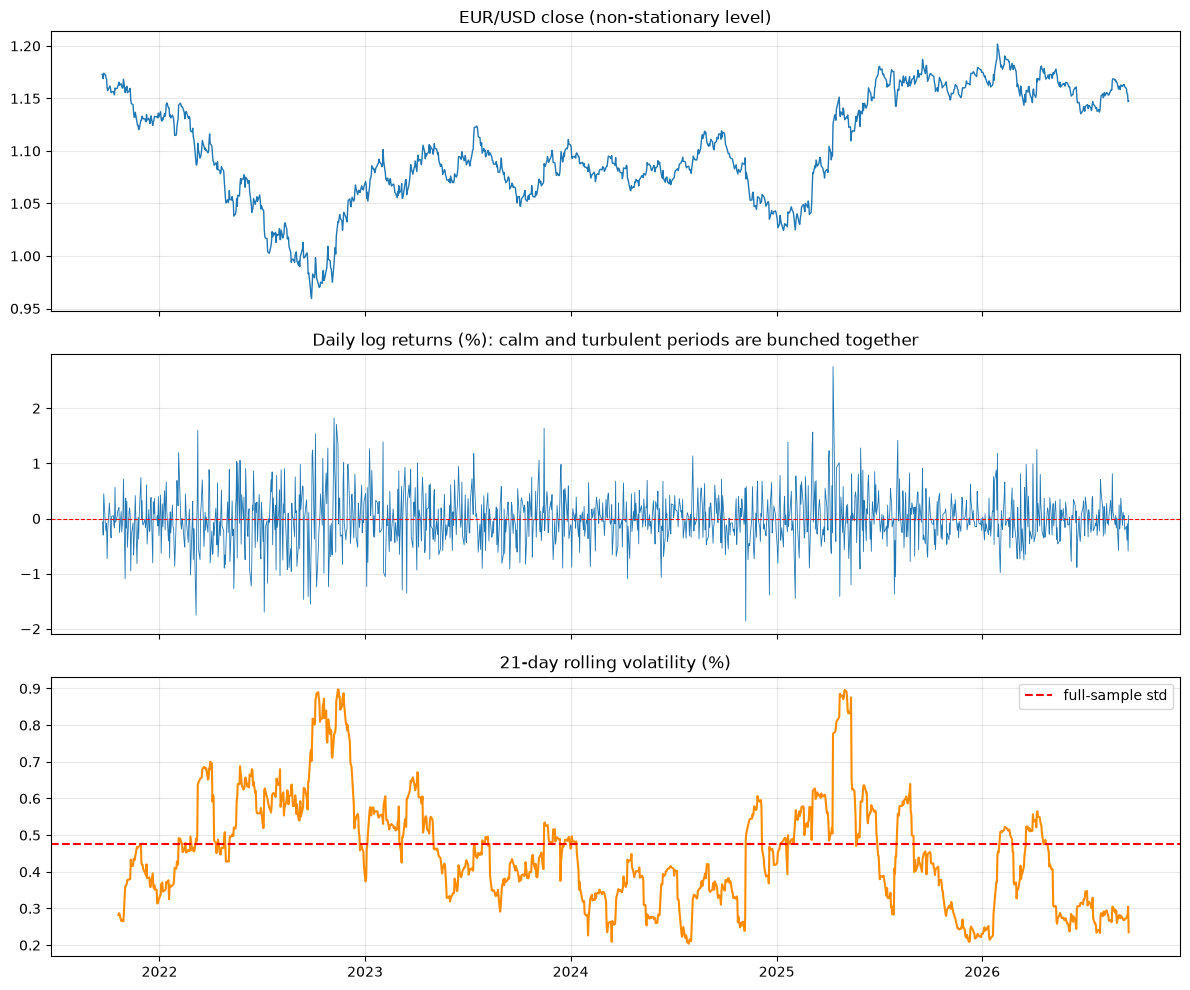

In [23]:
fig, ax = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
ax[0].plot(price, lw=1);                ax[0].set_title("EUR/USD close (non-stationary level)")
ax[1].plot(ret, lw=0.6);                ax[1].axhline(0, color="r", ls="--", lw=0.8)
ax[1].set_title("Daily log returns (%): calm and turbulent periods are bunched together")
roll = ret.rolling(21).std()
ax[2].plot(roll, color="darkorange");   ax[2].axhline(ret.std(), color="r", ls="--", label="full-sample std")
ax[2].set_title("21-day rolling volatility (%)"); ax[2].legend()
plt.tight_layout(); plt.show()

### 2b. Distribution shape: histogram vs Normal / Student-t, and QQ-plot
Tails sitting off the line in the QQ-plot (and a peaked centre) indicate excess kurtosis, which motivates Student-t innovations.

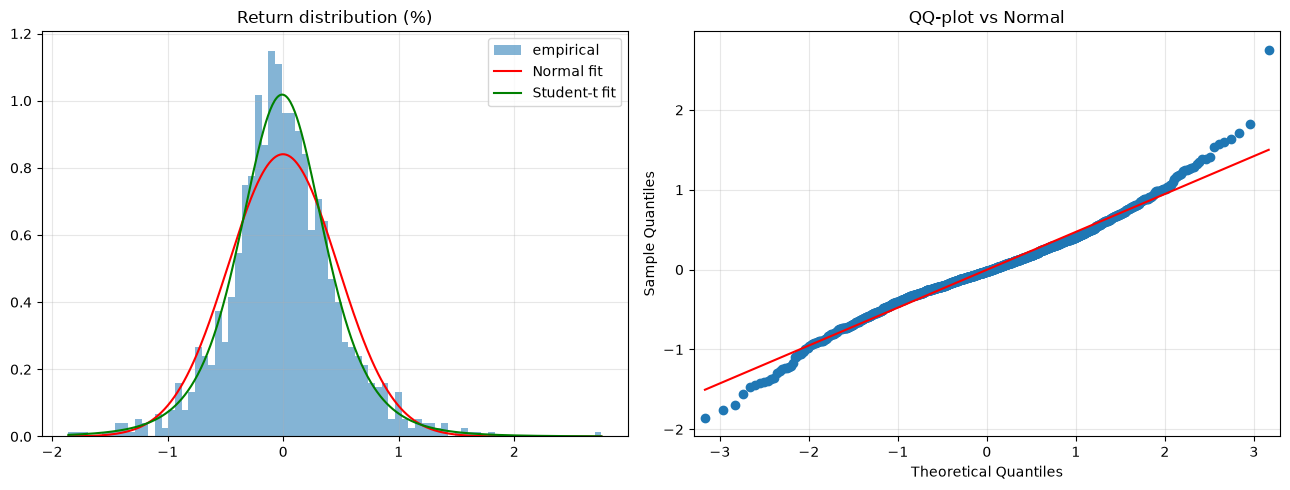

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].hist(ret, bins=80, density=True, alpha=0.55, label="empirical")
x = np.linspace(ret.min(), ret.max(), 500)
ax[0].plot(x, stats.norm.pdf(x, ret.mean(), ret.std()), "r", label="Normal fit")
ax[0].plot(x, stats.t.pdf(x, *stats.t.fit(ret)), "g", label="Student-t fit")
ax[0].set_title("Return distribution (%)"); ax[0].legend()
sm.qqplot(ret, line="s", ax=ax[1]); ax[1].set_title("QQ-plot vs Normal")
plt.tight_layout(); plt.show()

### 2c. Autocorrelation structure
Left: returns should be roughly inside the confidence band (nothing to model in the mean). Middle and right: squared and absolute returns should show significant, slowly decaying autocorrelation, which is exactly the dependence GARCH captures.

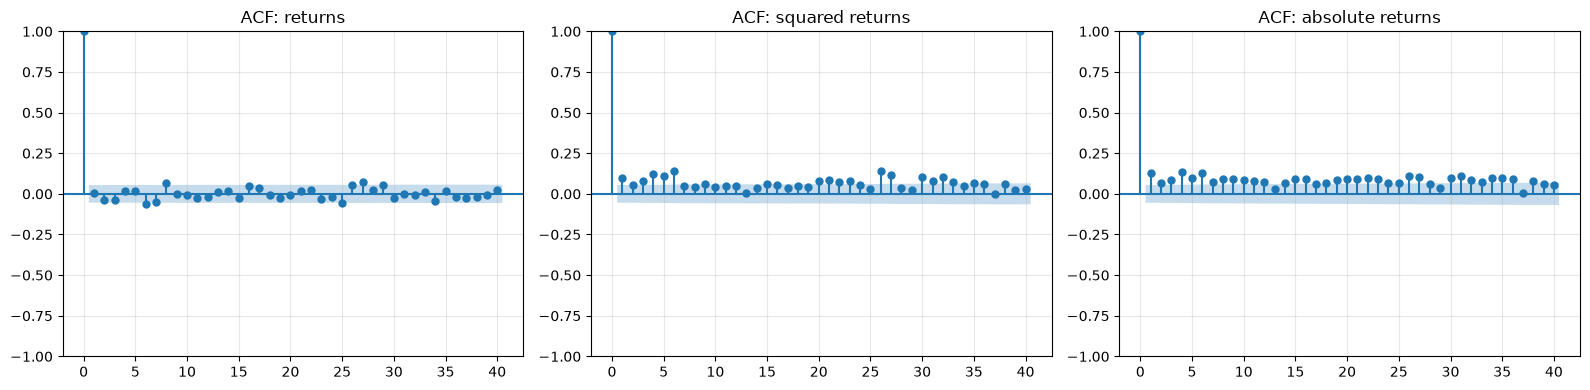

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
plot_acf(ret,        lags=40, ax=ax[0], title="ACF: returns")
plot_acf(ret**2,     lags=40, ax=ax[1], title="ACF: squared returns")
plot_acf(ret.abs(),  lags=40, ax=ax[2], title="ACF: absolute returns")
plt.tight_layout(); plt.show()

# Part 3: Train/test split and GARCH(1,1) estimation
Time-series data is split **chronologically** (no shuffling): first 80% to estimate, last 20% held out. We fit GARCH(1,1) with Normal and Student-t innovations by maximum likelihood on the training set only and pick the better one by BIC.

In [26]:
split = int(len(ret) * 0.8)
train, test = ret.iloc[:split], ret.iloc[split:]
print(f"Train: {len(train)} obs  ({train.index[0].date()} -> {train.index[-1].date()})")
print(f"Test : {len(test)} obs  ({test.index[0].date()} -> {test.index[-1].date()})")

Train: 1038 obs  (2021-09-22 -> 2025-09-17)
Test : 260 obs  (2025-09-18 -> 2026-09-18)


In [27]:
def fit_garch(series, dist):
    return arch_model(series, mean="Constant", vol="GARCH", p=1, q=1, dist=dist, rescale=False).fit(disp="off")

fits = {d: fit_garch(train, d) for d in ["normal", "t"]}
comparison = pd.DataFrame({d: {"Log-likelihood": f.loglikelihood, "AIC": f.aic, "BIC": f.bic}
                           for d, f in fits.items()}).T
best_dist = comparison["BIC"].idxmin()
res_train = fits[best_dist]
print(f"Selected innovation distribution (lowest BIC): {best_dist}\n")
display(comparison.round(2))
print(res_train.summary())

Selected innovation distribution (lowest BIC): t



,Log-likelihood,AIC,BIC
normal,-721.10,1450.21,1469.99
t,-698.66,1407.32,1432.05


                        Constant Mean - GARCH Model Results                         
Dep. Variable:               log_return_pct   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -698.662
Distribution:      Standardized Student's t   AIC:                           1407.32
Method:                  Maximum Likelihood   BIC:                           1432.05
                                              No. Observations:                 1038
Date:                      Thu, Oct 08 2026   Df Residuals:                     1037
Time:                              14:50:34   Df Model:                            1
                                  Mean Model                                  
                  coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------

### 3b. Parameter table and what the parameters mean
$\sigma_t^2=\omega+\alpha\epsilon_{t-1}^2+\beta\sigma_{t-1}^2$. **Persistence** $=\alpha+\beta$ must be below 1 for a stationary variance; the long-run variance is $\omega/(1-\alpha-\beta)$; a shock to volatility halves after $\ln 0.5/\ln(\alpha+\beta)$ days.

In [28]:
def std_quantile(p, dist, nu=None):
    """Quantile of a unit-variance Normal / Student-t shock."""
    if dist == "normal":
        return stats.norm.ppf(p)
    return stats.t.ppf(p, nu) * np.sqrt((nu - 2) / nu)

def draw_shocks(size, dist, nu, rng):
    """Unit-variance Normal / Student-t random shocks."""
    if dist == "normal":
        return rng.standard_normal(size)
    return rng.standard_t(nu, size) * np.sqrt((nu - 2) / nu)

p = res_train.params
param_table = pd.DataFrame({"coef": p, "std err": res_train.std_err,
                            "t-stat": res_train.tvalues, "p-value": res_train.pvalues})
display(param_table.round(5))

omega, alpha, beta = p["omega"], p["alpha[1]"], p["beta[1]"]
persistence = alpha + beta
long_run_var = omega / (1 - persistence)
print(f"alpha + beta (persistence)    : {persistence:.4f}  ({'stationary' if persistence < 1 else 'NOT stationary'})")
print(f"Long-run daily vol            : {np.sqrt(long_run_var):.4f}%   (annualised {np.sqrt(long_run_var*252):.2f}%)")
print(f"Volatility-shock half-life    : {np.log(0.5)/np.log(persistence):.1f} days")
if best_dist == "t":
    print(f"Student-t degrees of freedom  : {p['nu']:.2f}  (lower = fatter tails)")

,coef,std err,t-stat,p-value
mu,-0.00414,0.01325,-0.31247,0.75469
omega,0.00160,0.00118,1.35598,0.17510
alpha[1],0.02956,0.00800,3.69402,0.00022
beta[1],0.96541,0.00945,102.14082,0.00000
nu,6.49391,1.24724,5.20664,0.00000


alpha + beta (persistence)    : 0.9950  (stationary)
Long-run daily vol            : 0.5646%   (annualised 8.96%)
Volatility-shock half-life    : 137.5 days
Student-t degrees of freedom  : 6.49  (lower = fatter tails)


### 3c. In-sample diagnostics
A well-specified model leaves **standardised residuals** $\epsilon_t/\sigma_t$ with no remaining autocorrelation in levels or squares (Ljung-Box p > 0.05) and no ARCH effect left.

,p-value,Remaining structure?
"LB p-value, std. residuals (lag 10)",0.6524,No (good)
"LB p-value, squared std. res. (lag 10)",0.9749,No (good)
"ARCH-LM p-value, std. residuals",0.9739,No (good)


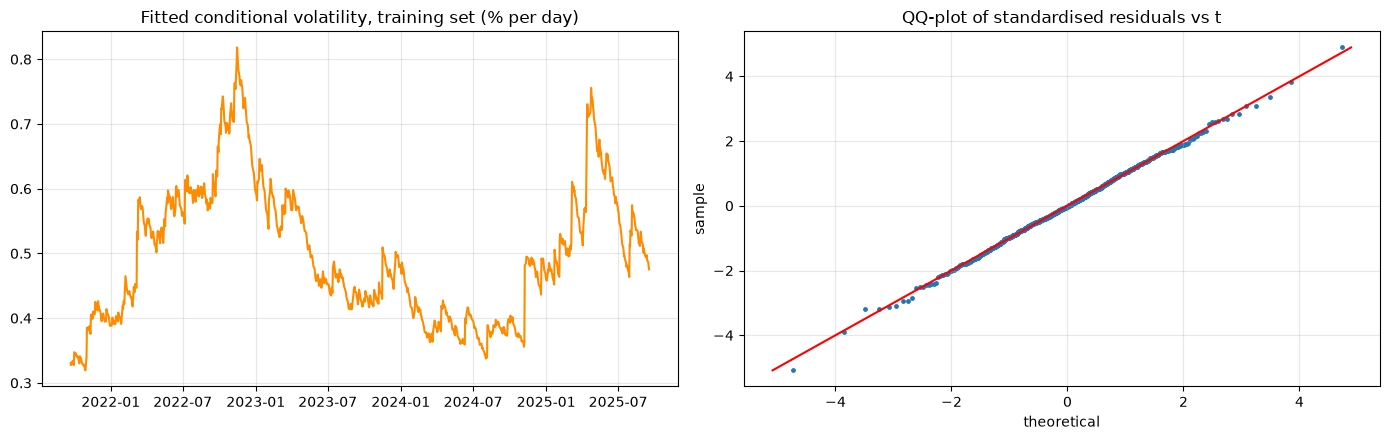

In [29]:
std_resid = res_train.std_resid.dropna()
diag = pd.Series({
    "LB p-value, std. residuals (lag 10)":   acorr_ljungbox(std_resid,    lags=[10], return_df=True)["lb_pvalue"].iloc[0],
    "LB p-value, squared std. res. (lag 10)": acorr_ljungbox(std_resid**2, lags=[10], return_df=True)["lb_pvalue"].iloc[0],
    "ARCH-LM p-value, std. residuals":        het_arch(std_resid, nlags=10)[1],
}).to_frame("p-value")
diag["Remaining structure?"] = np.where(diag["p-value"] < 0.05, "YES (model misses something)", "No (good)")
display(diag.round(4))

nu_hat = p.get("nu", np.nan)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(res_train.conditional_volatility, color="darkorange")
ax[0].set_title("Fitted conditional volatility, training set (% per day)")
sr = np.sort(std_resid.values)
theo = std_quantile((np.arange(1, len(sr) + 1) - 0.5) / len(sr), best_dist, nu_hat)
ax[1].scatter(theo, sr, s=6)
lim = [min(theo.min(), sr.min()), max(theo.max(), sr.max())]
ax[1].plot(lim, lim, "r"); ax[1].set_title(f"QQ-plot of standardised residuals vs {best_dist}")
ax[1].set_xlabel("theoretical"); ax[1].set_ylabel("sample")
plt.tight_layout(); plt.show()

# Part 4: Out-of-sample evaluation on the test set
**Method.** Parameters are frozen at their training-set values (`fix`). For each test day the model's volatility, which only uses information up to the previous day, is a genuine one-step-ahead forecast.

Volatility is not directly observable, so forecasts are scored against proxies: $(r_t-\mu)^2$ for variance and $|r_t-\mu|$ for volatility. This proxy is very noisy, so absolute RMSE values are not interpretable on their own; what matters is **how GARCH compares with simple benchmarks** (constant training-set volatility, and RiskMetrics EWMA with $\lambda=0.94$). Metrics: RMSE, MAE, QLIKE (robust loss for variance forecasts; lower is better) and the Mincer-Zarnowitz $R^2$ from regressing the variance proxy on the forecast.

In [30]:
mu_tr = res_train.params["mu"]

# GARCH: frozen training parameters applied to the full sample; take test-window values
am_all = arch_model(ret, mean="Constant", vol="GARCH", p=1, q=1, dist=best_dist, rescale=False)
sig_garch = am_all.fix(res_train.params).conditional_volatility.loc[test.index]

# Benchmarks
sig_static = pd.Series(train.std(), index=test.index)
ewma_var = (ret**2).ewm(alpha=1 - 0.94, adjust=False).mean().shift(1)    # uses data up to t-1 only
sig_ewma = np.sqrt(ewma_var.loc[test.index])

def evaluate(sig, actual, mu):
    sig = np.asarray(sig, float); a = np.asarray(actual, float)
    e2, h = (a - mu) ** 2, sig ** 2
    mz = np.nan if np.ptp(h) == 0 else sm.OLS(e2, sm.add_constant(h)).fit().rsquared
    return {"RMSE (variance)": np.sqrt(np.mean((e2 - h) ** 2)),
            "RMSE (volatility)": np.sqrt(np.mean((np.abs(a - mu) - sig) ** 2)),
            "MAE (volatility)": np.mean(np.abs(np.abs(a - mu) - sig)),
            "QLIKE": np.mean(np.log(h) + e2 / h),
            "Mincer-Zarnowitz R2": mz}

oos = pd.DataFrame({"GARCH(1,1) " + best_dist: evaluate(sig_garch, test, mu_tr),
                    "EWMA (0.94)":             evaluate(sig_ewma,  test, mu_tr),
                    "Constant vol (train)":    evaluate(sig_static, test, mu_tr)}).T
oos.round(5)

,RMSE (variance),RMSE (volatility),MAE (volatility),QLIKE,Mincer-Zarnowitz R2
"GARCH(1,1) t",0.21360,0.26077,0.22316,-1.10640,0.01830
EWMA (0.94),0.20839,0.23811,0.19573,-1.15058,0.03485
Constant vol (train),0.24837,0.32772,0.29574,-0.90328,NaN


### 4b. VaR backtest: how often are losses worse than the predicted VaR?
A 1-day VaR at level $p$ should be breached on about $p$ of the test days. This is the natural "accuracy" measure for a risk model (precision/recall-type classification metrics don't fit because GARCH forecasts *risk*, not direction).
* **Kupiec POF**: is the breach frequency consistent with $p$?
* **Christoffersen independence**: are breaches spread out, or do they cluster?
* **Conditional coverage** = both combined.

High p-values (> 0.05) mean the model is *not rejected*. With only ~250 test days there are few expected breaches at 1% (about 2-3), so the 1% test has low power. The 5% level is shown as a more informative companion.

In [31]:
def kupiec_pof(x, n, p):
    phat = x / n
    lr = -2 * (xlogy(n - x, 1 - p) + xlogy(x, p)) + 2 * (xlogy(n - x, 1 - phat) + xlogy(x, phat))
    return lr, 1 - stats.chi2.cdf(lr, 1)

def christoffersen_ind(hits):
    h = np.asarray(hits, int)
    n00 = np.sum((h[:-1] == 0) & (h[1:] == 0)); n01 = np.sum((h[:-1] == 0) & (h[1:] == 1))
    n10 = np.sum((h[:-1] == 1) & (h[1:] == 0)); n11 = np.sum((h[:-1] == 1) & (h[1:] == 1))
    pi01 = n01 / (n00 + n01) if (n00 + n01) else 0.0
    pi11 = n11 / (n10 + n11) if (n10 + n11) else 0.0
    pi   = (n01 + n11) / (n00 + n01 + n10 + n11)
    ll0 = xlogy(n00 + n10, 1 - pi) + xlogy(n01 + n11, pi)
    ll1 = xlogy(n00, 1 - pi01) + xlogy(n01, pi01) + xlogy(n10, 1 - pi11) + xlogy(n11, pi11)
    lr = max(-2 * (ll0 - ll1), 0.0)
    return lr, 1 - stats.chi2.cdf(lr, 1)

def backtest(threshold, actual, p):
    hits = (np.asarray(actual) < np.asarray(threshold)).astype(int)
    n, x = len(hits), int(hits.sum())
    lr_uc, p_uc = kupiec_pof(x, n, p)
    lr_ind, p_ind = christoffersen_ind(hits)
    p_cc = 1 - stats.chi2.cdf(lr_uc + lr_ind, 2)
    return {"Breaches": x, "Expected": round(n * p, 2), "Breach rate": x / n,
            "Coverage (1 - breach rate)": 1 - x / n,
            "Kupiec p": p_uc, "Independence p": p_ind, "Cond. coverage p": p_cc}

nu_tr = res_train.params.get("nu", np.nan)
rows = {}
for level in [0.01, 0.05]:
    q_g = std_quantile(level, best_dist, nu_tr)       # GARCH: model's own innovation distribution
    q_n = stats.norm.ppf(level)                       # benchmarks: Normal
    rows[(f"{int(level*100)}%", "GARCH(1,1) " + best_dist)] = backtest(mu_tr + q_g * sig_garch, test, level)
    rows[(f"{int(level*100)}%", "EWMA (0.94)")]             = backtest(mu_tr + q_n * sig_ewma, test, level)
    rows[(f"{int(level*100)}%", "Constant vol (train)")]    = backtest(mu_tr + q_n * sig_static, test, level)
bt = pd.DataFrame(rows).T
bt.index.names = ["VaR level", "Model"]
bt.round(4)

Breaches  Expected  Breach rate  \
VaR level Model                                                   
1%        GARCH(1,1) t               0.0       2.6       0.0000   
          EWMA (0.94)                2.0       2.6       0.0077   
          Constant vol (train)       0.0       2.6       0.0000   
5%        GARCH(1,1) t               8.0      13.0       0.0308   
          EWMA (0.94)                9.0      13.0       0.0346   
          Constant vol (train)       2.0      13.0       0.0077   

                                Coverage (1 - breach rate)  Kupiec p  \
VaR level Model                                                        
1%        GARCH(1,1) t                              1.0000    0.0222   
          EWMA (0.94)                               0.9923    0.6967   
          Constant vol (train)                      1.0000    0.0222   
5%        GARCH(1,1) t                              0.9692    0.1267   
          EWMA (0.94)                               0.9654    0.2293   
          Constant vol (train)                      0.9923    0.0001   

                                Independence p  Cond. coverage p  
VaR level Model                                                   
1%        GARCH(1,1) t                  1.0000            0.0733  
          EWMA (0.94)                   0.8600            0.9125  
          Constant vol (train)          1.0000            0.0733  
5%        GARCH(1,1) t                  0.4751            0.2414  
          EWMA (0.94)                   0.4208            0.3511  
          Constant vol (train)          0.8600            0.0005

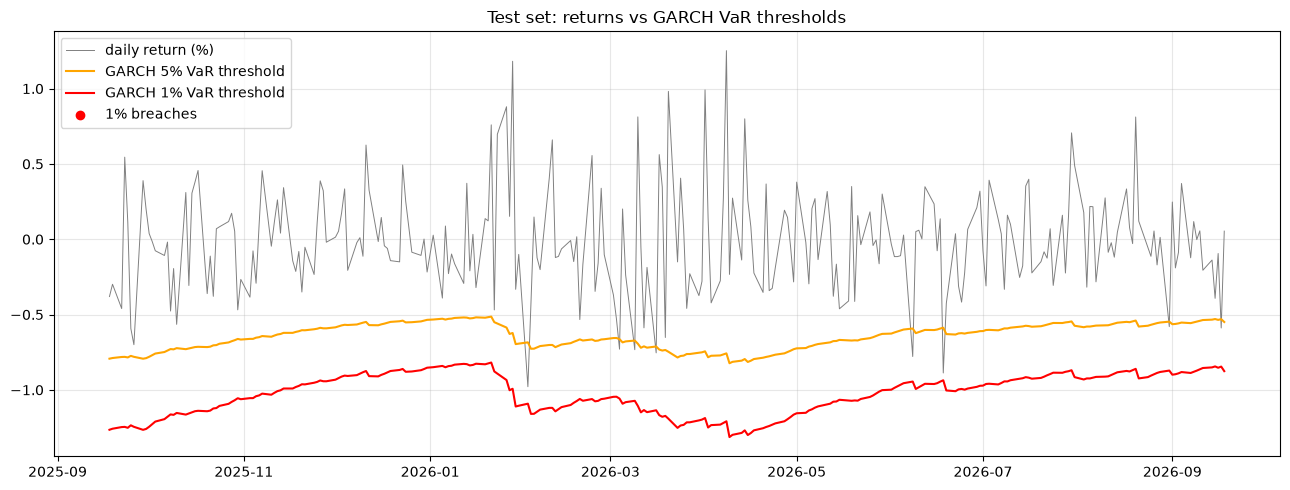

In [32]:
thr01 = mu_tr + std_quantile(0.01, best_dist, nu_tr) * sig_garch
thr05 = mu_tr + std_quantile(0.05, best_dist, nu_tr) * sig_garch
hit01 = test < thr01

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(test, lw=0.7, color="grey", label="daily return (%)")
ax.plot(thr05, color="orange", label="GARCH 5% VaR threshold")
ax.plot(thr01, color="red",    label="GARCH 1% VaR threshold")
ax.scatter(test.index[hit01], test[hit01], color="red", zorder=5, label="1% breaches")
ax.set_title("Test set: returns vs GARCH VaR thresholds"); ax.legend(); plt.tight_layout(); plt.show()

# Part 5: Monte Carlo simulation and 1% VaR
After validating on the hold-out, the model is **re-estimated on the full sample** so the volatility forecast uses the latest information, which is standard practice. 

**Portfolio.** \$100 held in EUR, marked to USD: $V_{T+1}=V_0\,S_{T+1}/S_T = V_0 e^{r_{T+1}}$ (a long EUR/USD position; for a *short* position look at the right tail instead).

**Steps.** (1) forecast $\sigma_{T+1}$ from the GARCH recursion, (2) draw 100,000 shocks $z_i$ from the fitted distribution, (3) $r_{T+1,i}=\mu+\sigma_{T+1}z_i$, (4) revalue the portfolio, (5) VaR$_{1\%}$ = \$100 minus the 1st percentile of simulated values.

In [33]:
res_final = arch_model(ret, mean="Constant", vol="GARCH", p=1, q=1, dist=best_dist, rescale=False).fit(disp="off")
pf = res_final.params
display(pf.to_frame("full-sample estimate").round(5))

sigma2_next = res_final.forecast(horizon=1, reindex=False).variance.iloc[-1, 0]     # in %^2
sigma_next = np.sqrt(sigma2_next)
print(f"Forecast next-day volatility sigma_(T+1): {sigma_next:.4f}%   (annualised {sigma_next*np.sqrt(252):.2f}%)")
print(f"Last observed conditional volatility    : {res_final.conditional_volatility.iloc[-1]:.4f}%")
print(f"Last spot S_T                           : {price.iloc[-1]:.5f}")

,full-sample estimate
mu,-0.00825
omega,0.00161
alpha[1],0.04262
beta[1],0.95172
nu,6.27571


Forecast next-day volatility sigma_(T+1): 0.3173%   (annualised 5.04%)
Last observed conditional volatility    : 0.3224%
Last spot S_T                           : 1.14760


In [34]:
N, V0, LEVEL = 100_000, 100.0, 0.01
rng = np.random.default_rng(42)
mu_f, nu_f = pf["mu"], pf.get("nu", np.nan)

# ---- 1-day Monte Carlo
z = draw_shocks(N, best_dist, nu_f, rng)
r1 = (mu_f + sigma_next * z) / 100                 # back to decimal log-return
S_T = price.iloc[-1]
S1 = S_T * np.exp(r1)                              # simulated EUR/USD rates
V1 = V0 * S1 / S_T                                 # simulated portfolio value
pnl1 = V1 - V0

cut = np.percentile(pnl1, LEVEL * 100)
VaR_1d = -cut
ES_1d = -pnl1[pnl1 <= cut].mean()

# ---- cross-checks
VaR_param = V0 * (1 - np.exp((mu_f + std_quantile(LEVEL, best_dist, nu_f) * sigma_next) / 100))
VaR_hist = -np.percentile(V0 * (np.exp(ret / 100) - 1), LEVEL * 100)
z_n = rng.standard_normal(N)
VaR_mc_normal = -np.percentile(V0 * (np.exp((mu_f + sigma_next * z_n) / 100) - 1), LEVEL * 100)

print(f"Simulated {N:,} EUR/USD rates: min {S1.min():.4f} | 1st pct {np.percentile(S1,1):.4f} | median {np.median(S1):.4f} | max {S1.max():.4f}")
print(f"\n1-day 99% VaR on ${V0:.0f} (Monte Carlo, GARCH-{best_dist}) : ${VaR_1d:.4f}  ({VaR_1d/V0:.3%} of portfolio)")
print(f"1-day 99% Expected Shortfall                        : ${ES_1d:.4f}")
print("\nCross-checks (1-day 99% VaR):")
print(f"  analytic GARCH quantile     : ${VaR_param:.4f}")
print(f"  MC with Normal shocks       : ${VaR_mc_normal:.4f}")
print(f"  plain historical simulation : ${VaR_hist:.4f}")

Simulated 100,000 EUR/USD rates: min 1.1031 | 1st pct 1.1382 | median 1.1475 | max 1.1793

1-day 99% VaR on $100 (Monte Carlo, GARCH-t) : $0.8206  (0.821% of portfolio)
1-day 99% Expected Shortfall                        : $1.0262

Cross-checks (1-day 99% VaR):
  analytic GARCH quantile     : $0.8160
  MC with Normal shocks       : $0.7442
  plain historical simulation : $1.2315


### 5b. Multi-day horizon: full GARCH path simulation
The square-root-of-time rule ignores volatility dynamics. Here each of the 100,000 paths evolves its own variance through the GARCH recursion $\sigma_{t+1}^2=\omega+\alpha\epsilon_t^2+\beta\sigma_t^2$ for $H$ days, so volatility can rise after simulated shocks.

In [35]:
H = 10
om_f, a_f, b_f = pf["omega"], pf["alpha[1]"], pf["beta[1]"]

var_t = np.full(N, sigma2_next)                    # first step: the one-step-ahead forecast
cum_ret = np.zeros(N)
for _ in range(H):
    eps = np.sqrt(var_t) * draw_shocks(N, best_dist, nu_f, rng)
    cum_ret += mu_f + eps
    var_t = om_f + a_f * eps**2 + b_f * var_t
pnl_H = V0 * np.exp(cum_ret / 100) - V0

VaR_Hd = -np.percentile(pnl_H, LEVEL * 100)
print(f"{H}-day 99% VaR, full GARCH paths : ${VaR_Hd:.4f}")
print(f"{H}-day 99% VaR, sqrt-time scaling : ${VaR_1d*np.sqrt(H):.4f}")

10-day 99% VaR, full GARCH paths : $2.5560
10-day 99% VaR, sqrt-time scaling : $2.5951


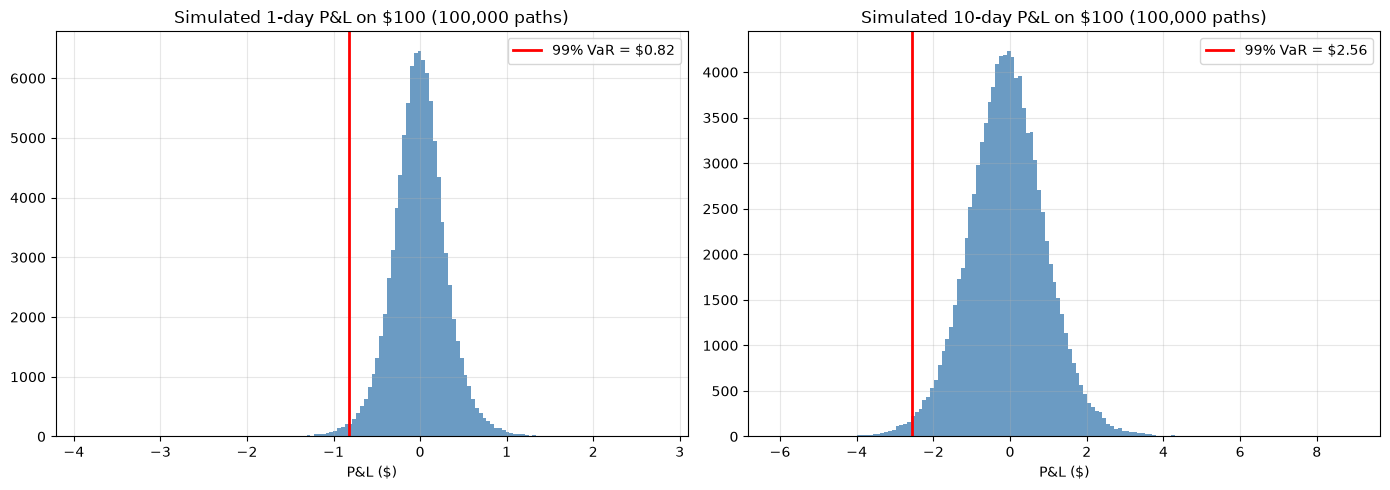

,99% VaR ($),99% VaR (% of portfolio),Expected shortfall ($)
Horizon,,,
1 day,0.8206,0.8206,1.0262
10 days,2.5560,2.5560,3.0573


In [36]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, pnl, var, title in [(ax[0], pnl1, VaR_1d, "1-day"), (ax[1], pnl_H, VaR_Hd, f"{H}-day")]:
    a.hist(pnl, bins=150, color="steelblue", alpha=0.8)
    a.axvline(-var, color="red", lw=2, label=f"99% VaR = ${var:.2f}")
    a.set_title(f"Simulated {title} P&L on ${V0:.0f} ({N:,} paths)")
    a.set_xlabel("P&L ($)"); a.legend()
plt.tight_layout(); plt.show()

summary = pd.DataFrame({
    "Horizon": ["1 day", f"{H} days"],
    "99% VaR ($)": [VaR_1d, VaR_Hd],
    "99% VaR (% of portfolio)": [VaR_1d / V0 * 100, VaR_Hd / V0 * 100],
    "Expected shortfall ($)": [ES_1d, -pnl_H[pnl_H <= np.percentile(pnl_H, 1)].mean()],
}).set_index("Horizon")
summary.round(4)

## Reading the results and caveats
* **VaR interpretation:** with 99% confidence, the portfolio should not lose more than the reported VaR over the horizon; on about 1 day in 100 it will. Expected shortfall is the average loss on those worst days.
* **Model validity** rests on Part 1 (ARCH effects present), Part 3c (residuals clean) and Part 4 (forecasts beat constant volatility, breach rate consistent with 1%/5%). If any of these fail, revisit the specification (e.g. GJR-GARCH/EGARCH, skewed-t, or an AR term in the mean).
* **Limitations:** single risk factor, constant-mean model, parameters assumed stable, and the 1% backtest has few expected breaches in a ~250-day test window (low statistical power). Re-estimate regularly and backtest on a rolling basis.